# Research Methods for AI & Data Science: 🏭 Industry Project, Running a Research Project End to End (Production-Style)

> **Who is this for?** Students and engineers who know how to train a model and now want to run a *complete, defensible study*: the kind you put in a thesis chapter, a paper, or an internal research report that a product team will act on. Every step is explained in plain English and every code line is commented.
>
> **What you will learn:** how to go from a question to a decision in 11 steps: research question and hypotheses → literature context → a **pre-registered analysis plan** → an experiment design with **baselines, an ablation, 10 seeds and nested cross-validation** → running it → **corrected resampled t-tests, bootstrap CIs and Holm correction** (checked against SciPy) → **publication-quality figures and a LaTeX table** → an **auto-generated results paragraph** → **limitations and threats to validity** → a **reproducibility package** → the **research → product handoff** in an industry team.
>
> **Prerequisites:** [02 Experiment design](02_experiment_design_for_ml.ipynb), [03 Statistical significance and reporting](03_statistical_significance_and_reporting.ipynb), [04 Reproducibility and research code](04_reproducibility_and_research_code.ipynb), [05 Paper writing and publishing](05_paper_writing_and_publishing.ipynb), [Statistics](../02_Data_Analysis/08_statistics.ipynb), [Logistic regression](../03_Machine_Learning/01_supervised/02_logistic_regression.ipynb), [Model evaluation](../03_Machine_Learning/06_model_evaluation/01_model_evaluation.ipynb).
>
> **Time needed:** about 2 hours. **Runs on:** CPU only (about 1–2 minutes of compute), no API key, no internet. All files go to a temporary folder that is deleted at the end.
>
> **Optional track:** part of the university-level fundamentals track (module 24, *Research Methods for AI & Data Science*); recommended for BS/MS AI students, thesis writers and interview prep for research / applied-scientist roles.

## Explained simply

In this notebook we run a small but **complete** research project from the first question to the final decision, exactly like a research team in a company would. The question is: *if a fraud detector is trained to pay more attention to the rare fraud cases, does it catch more fraud, and is that better than just making the detector more sensitive?* We decide the rules of the test **before** we look at the results, repeat the experiment many times so luck cannot fool us, use statistics to check whether the differences are real, and then write the figures, a results paragraph and a decision memo automatically from the numbers.

- **Everyday example 1, a smoke alarm:** you can make it catch more real fires by making it more sensitive, but then it also beeps when you make toast. "Catching more" always has a price in false alarms.
- **Everyday example 2, a fair football penalty test:** if you want to know whether new boots help, you decide beforehand how many penalties each player takes and what counts as a goal, otherwise you could keep shooting until the result looks good.

**Tiny concrete example:** out of 100 card payments, 4 are fraud. Detector A flags 2 payments and both are fraud: it caught 2 of 4 frauds (*recall* = 50%) with no false alarms. Detector B flags 20 payments and catches 3 frauds: recall = 75%, but 17 honest customers had their payment blocked. Which is better depends on what a missed fraud costs compared with an annoyed customer.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Pre-registration | writing down the test rules before seeing the results | clinical trials, A/B tests in tech companies |
| Recall vs. precision | "how many of the real cases did we catch?" vs. "how many alarms were real?" | fraud detection, spam filters, medical screening |
| Ablation | removing or changing one part to see if *that part* caused the improvement | ML papers ("what if we remove component X?") |

### How this notebook is different from related notebooks

| Related notebook | Its focus | This notebook |
|---|---|---|
| [06_model_evaluation/03 industry model comparison](../03_Machine_Learning/06_model_evaluation/03_industry_model_comparison_and_selection.ipynb) | champion vs challenger *model selection* with business cost | a *research study*: hypotheses, pre-registration, ablation, multiple-testing correction, paper outputs |
| [02 Experiment design](02_experiment_design_for_ml.ipynb) / [03 Statistical significance](03_statistical_significance_and_reporting.ipynb) | the theory: designs, power, threats to validity, tests, effect sizes | applies them to one complete study |
| [04 Reproducibility](04_reproducibility_and_research_code.ipynb) | the tools (seeds, configs, tracking, checksums) | uses them all together in one study |
| [05 Paper writing](05_paper_writing_and_publishing.ipynb) | how to write and publish | produces the actual figures, table and results text |
| [A/B testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb) | online experiments with users | the *offline* study that comes before an online test |

### The scenario

You are an applied scientist in the **risk research team of a payments company**. The fraud product team read a blog post claiming that *"class-balanced training triples fraud recall"* and asks: **should we retrain our fraud model with class-balanced weights?** Your manager wants an answer that is **reproducible, statistically sound and honest about its limits**, written so it could also become a workshop paper.

Real transaction data is confidential, so (like many papers) we use a **synthetic tabular dataset with a fraud-like class imbalance**. This is one of our threats to validity (Section 9).

### Table of contents
0. Setup and configuration
1. Research question and hypotheses
2. Literature context
3. The pre-registered analysis plan
4. Experiment design: baselines, ablation, 10 seeds, nested CV
5. Running the study
6. Statistical tests (checked against SciPy)
7. Publication-quality figures and a LaTeX table
8. An auto-generated results paragraph
9. Limitations and threats to validity
10. The reproducibility package
11. Inside an industry research team: from research to product
12. Summary, practice problems, resources

---
## 0. Setup and configuration

> 💡 **In plain English:** we load the tools and put every setting that can change a result in one place.

All settings that can change a result live in **one frozen config object**. The study will later save it into the reproducibility package.

In [1]:
# ---- Standard library ----
import hashlib                        # fingerprints of the plan, the data and the package files
import json
import platform
import re
import shutil
import tempfile                       # a private working folder (never write into the repo)
import time
import warnings
from dataclasses import asdict, dataclass, field
from datetime import datetime, timezone
from importlib import metadata
from pathlib import Path

# ---- Third-party ----
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import yaml
from IPython.display import Markdown, display
from scipy import stats                                   # reference implementations for our tests
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, brier_score_loss,
                             precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits               # control CPU threads used by NumPy / BLAS

warnings.filterwarnings("ignore")
threadpool_limits(limits=1)           # one BLAS thread: faster and more repeatable on a shared CPU
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)


@dataclass(frozen=True)
class StudyConfig:
    # data (synthetic, fraud-like)
    data_seed: int = 2026
    n_samples: int = 3000
    n_features: int = 20
    n_informative: int = 8
    n_redundant: int = 4
    minority_share: float = 0.04          # about 4% "fraud"
    class_sep: float = 1.2
    label_noise: float = 0.01
    # protocol
    seeds: tuple = tuple(range(10))       # fixed in advance: 10 repetitions
    outer_folds: int = 5                  # outer CV: estimates performance
    inner_folds: int = 3                  # inner CV: tunes C (never sees the outer test fold)
    C_grid: tuple = (0.01, 0.1, 1.0, 10.0)
    inner_metric: str = "average_precision"
    max_iter: int = 2000
    # statistics
    alpha: float = 0.05
    n_bootstrap: int = 10_000
    sesoi_recall: float = 0.05            # smallest effect size of interest for recall (absolute)


CFG = StudyConfig()
WORK = Path(tempfile.mkdtemp(prefix="research_study_"))          # all outputs go here
(WORK / "figures").mkdir()
STUDY_START = time.perf_counter()
print(f"Python {platform.python_version()} | numpy {np.__version__} | scipy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}")
print(json.dumps(asdict(CFG)))

Python 3.12.3 | numpy 2.4.6 | scipy 1.18.0 | scikit-learn 1.9.0 | pandas 2.3.3 | matplotlib 3.11.0
{"data_seed": 2026, "n_samples": 3000, "n_features": 20, "n_informative": 8, "n_redundant": 4, "minority_share": 0.04, "class_sep": 1.2, "label_noise": 0.01, "seeds": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], "outer_folds": 5, "inner_folds": 3, "C_grid": [0.01, 0.1, 1.0, 10.0], "inner_metric": "average_precision", "max_iter": 2000, "alpha": 0.05, "n_bootstrap": 10000, "sesoi_recall": 0.05}


---
## 1. Research question and hypotheses

> 💡 **In plain English:** we turn a vague question into a precise one, with hypotheses that a test can confirm or reject.

A good research question is **specific, answerable with the data you have, and tied to a decision**.

> **RQ:** On imbalanced, fraud-like tabular data, does class-balanced training of logistic regression improve **minority-class recall**, and is any improvement more than what simply **moving the decision threshold** of an unweighted model achieves?

We turn it into **pre-specified hypotheses**. Each has a null hypothesis $H_0$ (no difference) that a statistical test can reject.

| ID | Comparison | Metric | $H_0$ | Why we care |
|---|---|---|---|---|
| **H1** (primary) | Weighted (T) vs unweighted (B1), both at threshold 0.5 | minority recall | equal recall | the blog's claim |
| **H2** | T vs B1 | precision | equal precision | the price of extra recall (false alarms) |
| **H3** | T vs B1 | PR-AUC (average precision) | equal PR-AUC | does weighting improve *ranking*, or only shift the threshold? |
| **H4** | T vs threshold-moving ablation (A1) | minority recall | equal recall | is weighting better than the free alternative? |

All tests are **two-sided** at $\alpha = 0.05$, with **Holm correction** across the family {H1, H2, H3, H4}. We also fix a **smallest effect size of interest** (SESOI): a recall difference below 0.05 is too small to matter for the product, even if it is "significant".

> 🎓 **Exam / interview tip:** "What makes a good hypothesis?" It is falsifiable, states the comparison, the metric and the direction (or two-sidedness) *before* seeing data, and is linked to a decision.

---
## 2. Literature context

> 💡 **In plain English:** we summarise what other researchers already found, so we know what is new about our study.

A short, honest summary of what is known (in a real paper you would expand this into a related-work section with a systematic search; see [notebook 01](01_research_methodology_and_literature_review.ipynb) of this module):

- **Learning from imbalanced data** is a long-studied problem; He & Garcia (*IEEE TKDE*, 2009) survey re-sampling, cost-sensitive and algorithmic approaches. **SMOTE** (Chawla et al., *JAIR*, 2002) is the best-known over-sampling method.
- **Cost-sensitive learning:** Elkan (*IJCAI*, 2001) showed that for a classifier with calibrated probabilities, the optimal decision under misclassification costs is a **threshold** on the predicted probability, and that changing the class proportions (or weights) in training is closely related to changing that threshold. This motivates our **threshold-moving ablation**.
- **Clinical prediction:** van den Goorbergh et al. (*JAMIA*, 2022) found in simulations with logistic regression that imbalance corrections (re-sampling/weighting) did not improve discrimination (AUROC) and made predicted risks badly **miscalibrated**.
- **Metrics:** Saito & Rehmsmeier (*PLOS ONE*, 2015) argue that precision–recall plots are more informative than ROC plots on imbalanced data, so we use **PR-AUC**.
- **Comparing algorithms:** Dietterich (*Neural Computation*, 1998) and Nadeau & Bengio (*Machine Learning*, 2003) showed that naive t-tests on cross-validation results are too optimistic because the training sets overlap; Nadeau & Bengio proposed a **corrected resampled t-test**, and Bouckaert & Frank (PAKDD 2004) studied it for repeated CV. **Nested CV** is needed when hyper-parameters are tuned (Varma & Simon, *BMC Bioinformatics*, 2006; Cawley & Talbot, *JMLR*, 2010). Holm (1979) gives a simple, uniformly more powerful alternative to Bonferroni.

**The gap we address:** applied reports often compare weighted and unweighted models at a fixed 0.5 threshold and with a single split, which mixes up "better model" with "different threshold" and ignores seed variance.

> ⚠️ **Common mistake:** citing papers you have not read, or that an AI tool suggested without checking. Every reference above is a real, widely cited paper; in your own work, verify each one (notebook 05, Section 10).

---
## 3. The pre-registered analysis plan

> 💡 **In plain English:** we write down the full plan, including how we will decide, before running anything, and lock it with a fingerprint.

**Pre-registration** means writing down the hypotheses, data, metrics, analysis and decision rules **before** running the study, so that you cannot (even unconsciously) change them after seeing the results. Public registries (e.g. OSF Registries, AsPredicted) timestamp the plan; some ML venues and workshops accept *pre-registered papers* that are reviewed before the experiments are run. Inside a company, the same role is played by a design document approved before the experiment. (Templates and the theory behind analysis plans are in [notebook 02](02_experiment_design_for_ml.ipynb), Section 6.)

We store the plan as YAML and **fingerprint it with SHA-256**; at the end we re-hash it to prove it was not edited.

In [2]:
PLAN = {
    "title": "Class-balanced training and minority recall on fraud-like tabular data",
    "registered_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "research_question": "Does class-balanced logistic regression improve minority recall, beyond threshold moving?",
    "data": {"generator": "sklearn.datasets.make_classification", "seed": CFG.data_seed,
             "n_samples": CFG.n_samples, "minority_share": CFG.minority_share},
    "conditions": {
        "B0": "DummyClassifier(strategy='stratified'): sanity floor",
        "B1": "LogisticRegression, unweighted, threshold 0.5",
        "T": "LogisticRegression, class_weight='balanced', threshold 0.5",
        "A1": "ablation: the B1 model, threshold = minority share of the training fold",
    },
    "protocol": {"seeds": list(CFG.seeds), "outer_folds": CFG.outer_folds, "inner_folds": CFG.inner_folds,
                 "C_grid": list(CFG.C_grid), "inner_selection_metric": CFG.inner_metric},
    "metrics": {"primary": "minority recall", "secondary": ["precision", "PR-AUC (average precision)"],
                "exploratory": ["balanced accuracy", "Brier score", "mean predicted probability"]},
    "hypotheses": {"H1": "recall T != B1", "H2": "precision T != B1", "H3": "PR-AUC T != B1",
                   "H4": "recall T != A1"},
    "analysis": {"test": "two-sided corrected resampled t-test (Nadeau & Bengio 2003) on the 50 paired outer-fold scores",
                 "multiplicity": "Holm over H1-H4", "alpha": CFG.alpha,
                 "effect_size": "mean paired difference with corrected 95% CI; seed-level bootstrap CI as a descriptive check",
                 "sesoi_recall": CFG.sesoi_recall},
    "decision_rule": "Recommend weighting only if H4 is rejected in favour of T with a recall gain >= SESOI.",
    "exclusions": "none; every run is reported",
    "stopping_rule": "fixed: exactly 10 seeds, no additional runs after looking at results",
}
PLAN_YAML = yaml.safe_dump(PLAN, sort_keys=False, width=110)
PLAN_SHA = hashlib.sha256(PLAN_YAML.encode()).hexdigest()
(WORK / "preregistration.yaml").write_text(PLAN_YAML)
print(PLAN_YAML)
print("plan SHA-256:", PLAN_SHA)

title: Class-balanced training and minority recall on fraud-like tabular data
registered_at_utc: '2026-10-27T08:55:59+00:00'
research_question: Does class-balanced logistic regression improve minority recall, beyond threshold moving?
data:
  generator: sklearn.datasets.make_classification
  seed: 2026
  n_samples: 3000
  minority_share: 0.04
conditions:
  B0: 'DummyClassifier(strategy=''stratified''): sanity floor'
  B1: LogisticRegression, unweighted, threshold 0.5
  T: LogisticRegression, class_weight='balanced', threshold 0.5
  A1: 'ablation: the B1 model, threshold = minority share of the training fold'
protocol:
  seeds:
  - 0
  - 1
  - 2
  - 3
  - 4
  - 5
  - 6
  - 7
  - 8
  - 9
  outer_folds: 5
  inner_folds: 3
  C_grid:
  - 0.01
  - 0.1
  - 1.0
  - 10.0
  inner_selection_metric: average_precision
metrics:
  primary: minority recall
  secondary:
  - precision
  - PR-AUC (average precision)
  exploratory:
  - balanced accuracy
  - Brier score
  - mean predicted probability
hypoth

**What just happened?** The full plan, including the **decision rule** and the **stopping rule**, is frozen and fingerprinted before any model is trained. Anything we do later that is not in the plan must be labelled **exploratory** (or reported as a **deviation** with a reason).

---
## 4. Experiment design: baselines, ablation, 10 seeds, nested CV

> 💡 **In plain English:** we compare a do-nothing baseline, the normal model, the weighted model and a simpler alternative, many times over.

### 4.1 The data

In [3]:
X, y = make_classification(
    n_samples=CFG.n_samples, n_features=CFG.n_features, n_informative=CFG.n_informative,
    n_redundant=CFG.n_redundant, weights=[1 - CFG.minority_share], flip_y=CFG.label_noise,
    class_sep=CFG.class_sep, random_state=CFG.data_seed)
DATA_SHA = hashlib.sha256(np.ascontiguousarray(X).tobytes() + np.ascontiguousarray(y).tobytes()).hexdigest()
counts = np.bincount(y)
print(f"X shape {X.shape} | class counts {counts.tolist()} | minority share {y.mean():.2%}")
print("data SHA-256:", DATA_SHA[:16], "...")

X shape (3000, 20) | class counts [2868, 132] | minority share 4.40%
data SHA-256: 31e207ec8caea190 ...


### 4.2 The conditions

| Code | Condition | Role |
|---|---|---|
| **B0** | `DummyClassifier(strategy="stratified")`: random guesses with the class frequencies | **sanity floor**: any real model must beat it |
| **B1** | logistic regression, unweighted, predict fraud if $\hat p \ge 0.5$ | **standard baseline** |
| **T** | logistic regression, `class_weight="balanced"`, threshold 0.5 | **treatment** |
| **A1** | the *same fitted model as B1*, threshold $\tau = \pi_{\text{train}}$ (the minority share of the training fold) | **ablation**: keeps everything of B1, changes only the threshold |

**Why this ablation?** With balanced weights, each minority example counts $n_0/n_1$ times as much as a majority example. For a well-specified, lightly regularised logistic model, that multiplies the predicted *odds* by about $n_0/n_1$, so "weighted $\hat p_w \ge 0.5$" behaves like "unweighted $\hat p \ge n_1/n = \pi$":

$$
\frac{\hat p_w}{1-\hat p_w} \approx \frac{n_0}{n_1}\cdot\frac{\hat p}{1-\hat p} \ge 1
\quad\Longleftrightarrow\quad \hat p \ge \frac{n_1}{n_0+n_1} = \pi .
$$

So A1 isolates the **threshold effect** of weighting. If T ≈ A1, the gain comes from the threshold, not from a better model.

### 4.3 Nested cross-validation with 10 seeds

Hyper-parameter $C$ is tuned **inside** each outer training set, so the outer test fold is never used for any decision (otherwise the estimate is optimistically biased; Varma & Simon, 2006):

```
for seed in 0..9:                                   # 10 repetitions with different shuffles
    outer = StratifiedKFold(5, shuffle=True, random_state=seed)
    for (train, test) in outer:                     # 5 outer folds -> 50 evaluations per condition
        for each condition B1 / T:
            inner = StratifiedKFold(3) on `train` only
            pick C from {0.01, 0.1, 1, 10} by mean inner PR-AUC
            refit on all of `train` with the chosen C (scaler fitted on `train` only)
        score B0, B1, T, A1 on `test`               # all four share the same split -> PAIRED design
```

**Cost:** per seed and outer fold we fit $2 \times (|C\text{-grid}| \times 3 + 1) = 26$ logistic regressions, so $10 \times 5 \times 26 = 1300$ fits in total, each on ≈ 2400 rows (well under a second each on a CPU).

In [4]:
def fit_logreg(X_tr, y_tr, C: float, class_weight) -> tuple:
    """Fit scaler + logistic regression on training data only; returns both (no leakage)."""
    scaler = StandardScaler().fit(X_tr)
    model = LogisticRegression(C=C, class_weight=class_weight, max_iter=CFG.max_iter)
    model.fit(scaler.transform(X_tr), y_tr)
    return scaler, model


def select_C(X_tr, y_tr, class_weight, seed: int) -> float:
    """Inner CV: choose C by mean average precision. Uses ONLY the outer training data."""
    inner = StratifiedKFold(CFG.inner_folds, shuffle=True, random_state=seed)
    best_C, best_score = None, -np.inf
    for C in CFG.C_grid:
        scores = []
        for i_tr, i_va in inner.split(X_tr, y_tr):
            scaler, model = fit_logreg(X_tr[i_tr], y_tr[i_tr], C, class_weight)
            p = model.predict_proba(scaler.transform(X_tr[i_va]))[:, 1]
            scores.append(average_precision_score(y_tr[i_va], p))
        if np.mean(scores) > best_score:                      # ties keep the smaller C (stronger penalty)
            best_C, best_score = C, np.mean(scores)
    return best_C


def score(y_true, y_pred, p) -> dict:
    """All pre-registered metrics for one condition on one outer test fold."""
    return {
        "recall": recall_score(y_true, y_pred),                               # primary
        "precision": precision_score(y_true, y_pred, zero_division=0),        # secondary
        "pr_auc": average_precision_score(y_true, p),                         # secondary (threshold-free)
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),              # exploratory
        "brier": brier_score_loss(y_true, p),                                 # exploratory (calibration)
        "mean_pred": float(np.mean(p)),                                       # exploratory (calibration)
    }

print("helper functions defined")

helper functions defined


---
## 5. Running the study

> 💡 **In plain English:** we run all 1,300 model fits exactly as planned and check for bugs before looking at statistics.

The loop below follows the plan exactly. We also keep the out-of-fold predictions of seed 0 for a figure, and the chosen $C$ values.

In [5]:
rows, oof = [], {"y": np.zeros(len(y)), "B1": np.zeros(len(y)), "T": np.zeros(len(y))}
t0 = time.perf_counter()
for seed in CFG.seeds:
    outer = StratifiedKFold(CFG.outer_folds, shuffle=True, random_state=seed)
    for fold, (tr, te) in enumerate(outer.split(X, y)):
        X_tr, y_tr, X_te, y_te = X[tr], y[tr], X[te], y[te]
        prior = y_tr.mean()                                                     # minority share of this training fold

        # B0: sanity floor
        dummy = DummyClassifier(strategy="stratified", random_state=seed).fit(X_tr, y_tr)
        p_b0 = dummy.predict_proba(X_te)[:, 1]
        results = {"B0": (dummy.predict(X_te), p_b0, np.nan)}

        # B1 and T: tuned by inner CV, refit on the whole outer training set
        for cond, weight in (("B1", None), ("T", "balanced")):
            C = select_C(X_tr, y_tr, weight, seed)
            scaler, model = fit_logreg(X_tr, y_tr, C, weight)
            p = model.predict_proba(scaler.transform(X_te))[:, 1]
            results[cond] = ((p >= 0.5).astype(int), p, C)
            if cond == "B1":                                                    # A1 = same model, other threshold
                results["A1"] = ((p >= prior).astype(int), p, C)
            if seed == 0:
                oof[cond][te] = p
        if seed == 0:
            oof["y"][te] = y_te

        for cond, (y_pred, p, C) in results.items():
            rows.append({"seed": seed, "fold": fold, "condition": cond, "C": C, "n_test": len(te),
                         "n_train": len(tr), **score(y_te, y_pred, p)})
runtime = time.perf_counter() - t0

res = pd.DataFrame(rows)
res.to_csv(WORK / "results_per_fold.csv", index=False)
ORDER = ["B0", "B1", "T", "A1"]
summary = (res.groupby("condition")[["recall", "precision", "pr_auc", "balanced_acc", "brier", "mean_pred"]]
              .agg(["mean", "std"]).loc[ORDER])
print(f"{len(res)} rows = {len(CFG.seeds)} seeds x {CFG.outer_folds} folds x {len(ORDER)} conditions | "
      f"compute time {runtime:.0f} s")
print(summary.round(3))

200 rows = 10 seeds x 5 folds x 4 conditions | compute time 36 s
          recall        precision        pr_auc        balanced_acc         brier        mean_pred       
            mean    std      mean    std   mean    std         mean    std   mean    std      mean    std
condition                                                                                                
B0         0.050  0.043     0.052  0.046  0.046  0.004        0.503  0.023  0.083  0.008     0.043  0.007
B1         0.370  0.098     0.902  0.086  0.594  0.087        0.684  0.049  0.026  0.003     0.044  0.004
T          0.726  0.067     0.163  0.017  0.541  0.094        0.777  0.034  0.132  0.007     0.324  0.012
A1         0.752  0.064     0.162  0.019  0.594  0.087        0.785  0.032  0.026  0.003     0.044  0.004


In [6]:
# Sanity checks: they protect against silent bugs before we run any statistics
b0_recall = res.loc[res.condition == "B0", "recall"].mean()
assert abs(b0_recall - y.mean()) < 0.05, "a random stratified guesser should have recall close to the minority share"
same_scores = np.allclose(res.loc[res.condition == "B1", "pr_auc"].values, res.loc[res.condition == "A1", "pr_auc"].values)
assert same_scores, "A1 re-uses the B1 model, so its PR-AUC must be identical"
assert res.groupby("condition").size().eq(len(CFG.seeds) * CFG.outer_folds).all()
print(f"B0 recall {b0_recall:.3f} ~ minority share {y.mean():.3f}: OK")
print("A1 and B1 have identical PR-AUC (same model): OK")
print("\nChosen C per condition (counts over 50 outer folds):")
print(res[res.condition.isin(["B1", "T"])].groupby("condition")["C"].value_counts().unstack(fill_value=0))

B0 recall 0.050 ~ minority share 0.044: OK
A1 and B1 have identical PR-AUC (same model): OK

Chosen C per condition (counts over 50 outer folds):
C          0.01   0.10   1.00   10.00
condition                            
B1             0     26     12     12
T             46      4      0      0


**What just happened?** All 50 outer folds were evaluated for every condition (the compute time is printed above), and the sanity checks passed: the dummy has recall close to the minority share, and A1 has exactly the PR-AUC of B1 because it is the same model. Already in the summary table we can see the story:

- **T** (weighted) has about twice the recall of **B1** (0.726 vs 0.370) but a much lower precision (0.163 vs 0.902).
- **A1**, the unweighted model with a moved threshold, reaches a similar recall (0.752) and precision (0.162) **without any re-training**.
- T has a *lower* PR-AUC than B1 (0.541 vs 0.594) and its average predicted probability (0.324) is far above the true fraud rate (0.044).

Also notice the chosen $C$: the inner CV almost always picked the strongest penalty ($C = 0.01$) for the weighted model, but mostly $C \ge 0.1$ for the unweighted one. Tuning interacts with weighting, which is exactly why both conditions must get the **same** tuning procedure. But a table of means is not evidence yet: next we test the pre-registered hypotheses.

---
## 6. Statistical tests (checked against SciPy)

> 💡 **In plain English:** we check whether the differences are real or just luck, using tests that we verify against SciPy.

### 6.1 Why a naive paired t-test is wrong here

For each of the $k = 50$ (seed, fold) pairs we have a paired difference $d_j = \text{score}_T - \text{score}_{B1}$. A naive paired t-test treats the 50 differences as independent, but they are not: the training sets of different folds and seeds **overlap heavily** (each pair of 5-fold training sets shares 75% of its rows), so the variance of $\bar d$ is underestimated and p-values are too small (Dietterich, 1998; Nadeau & Bengio, 2003).

The **corrected resampled t-test** (Nadeau & Bengio, 2003; Bouckaert & Frank, 2004) inflates the variance:

$$
t = \frac{\bar d}{\sqrt{\left(\frac{1}{k} + \frac{n_{\text{test}}}{n_{\text{train}}}\right)\hat\sigma^2_d}}, \qquad \text{df} = k - 1,
$$

where $\hat\sigma^2_d$ is the sample variance of the $d_j$. The naive test is the same formula with only $1/k$. With 5-fold CV, $n_{\text{test}}/n_{\text{train}} = 1/4$, so the variance is multiplied by $(1/50 + 1/4)/(1/50) = 13.5$ and $t$ shrinks by $\sqrt{13.5} \approx 3.7$.

(The theory of these tests, plus alternatives such as McNemar's test and the Bayesian correlated t-test, is in [notebook 03](03_statistical_significance_and_reporting.ipynb); here we apply them.) We implement it from scratch and first check that **without the correction** it reproduces `scipy.stats.ttest_rel` exactly.

In [7]:
def paired(metric: str, a: str, b: str) -> pd.DataFrame:
    """Scores of conditions a and b side by side, one row per (seed, fold), plus the difference a - b."""
    wide = res.pivot_table(index=["seed", "fold"], columns="condition", values=metric)
    return pd.DataFrame({"a": wide[a], "b": wide[b], "d": wide[a] - wide[b]})


def corrected_ttest(d: np.ndarray, n_train: int, n_test: int, corrected: bool = True, alpha: float = 0.05) -> dict:
    """Two-sided (corrected) resampled paired t-test and its (1 - alpha) CI for the mean difference."""
    k = len(d)
    factor = (1 / k + n_test / n_train) if corrected else 1 / k          # the only difference
    se = np.sqrt(factor * np.var(d, ddof=1))                              # standard error of the mean difference
    t = np.mean(d) / se
    p = 2 * stats.t.sf(abs(t), df=k - 1)                                  # two-sided p-value
    half = stats.t.ppf(1 - alpha / 2, df=k - 1) * se                      # CI half-width
    return {"mean_diff": np.mean(d), "t": t, "p": p, "ci_low": np.mean(d) - half, "ci_high": np.mean(d) + half}


n_tr, n_te = int(res.n_train.mean()), int(res.n_test.mean())
pr = paired("recall", "T", "B1")
ours_naive = corrected_ttest(pr.d.values, n_tr, n_te, corrected=False)
scipy_naive = stats.ttest_rel(pr.a, pr.b)
print(f"naive, ours : t = {ours_naive['t']:.4f}, p = {ours_naive['p']:.3e}")
print(f"naive, SciPy: t = {scipy_naive.statistic:.4f}, p = {scipy_naive.pvalue:.3e}")
assert np.isclose(ours_naive["t"], scipy_naive.statistic) and np.isclose(ours_naive["p"], scipy_naive.pvalue)

# a second check of the p-value formula: SciPy's one-sample test on the differences
assert np.isclose(stats.ttest_1samp(pr.d, 0).pvalue, ours_naive["p"])
ours_corr = corrected_ttest(pr.d.values, n_tr, n_te, corrected=True)
print(f"corrected  : t = {ours_corr['t']:.4f}, p = {ours_corr['p']:.3e}  "
      f"(t shrank by a factor {ours_naive['t'] / ours_corr['t']:.2f})")
print(f"n_train = {n_tr}, n_test = {n_te}")

naive, ours : t = 29.4458, p = 8.106e-33
naive, SciPy: t = 29.4458, p = 8.106e-33
corrected  : t = 8.0141, p = 1.818e-10  (t shrank by a factor 3.67)
n_train = 2400, n_test = 600


**What just happened?** Our naive version matches SciPy's `ttest_rel` (and `ttest_1samp` on the differences) to machine precision, so the formula and the p-value computation are right. The corrected statistic is smaller by $\sqrt{13.5} \approx 3.67$, exactly as predicted by the formula.

### 6.2 All pre-registered tests + Holm correction

**Holm's step-down procedure** controls the family-wise error rate (the probability of at least one false rejection) at $\alpha$ and is never less powerful than Bonferroni. Sort the $m$ p-values $p_{(1)} \le \dots \le p_{(m)}$; the adjusted p-values are

$$
\tilde p_{(i)} = \max_{j \le i}\ \min\bigl(1,\ (m - j + 1)\, p_{(j)}\bigr),
$$

and we reject $H_{(i)}$ if $\tilde p_{(i)} \le \alpha$. SciPy has no Holm function, so we check our implementation against a brute-force version of the definition and, if it is installed, against `statsmodels`.

In [8]:
def holm(pvalues) -> np.ndarray:
    """Holm-adjusted p-values (same order as the input)."""
    p = np.asarray(pvalues, dtype=float)
    m = len(p)
    order = np.argsort(p)                                      # smallest p first
    adjusted_sorted = np.minimum(1, (m - np.arange(m)) * p[order])
    adjusted_sorted = np.maximum.accumulate(adjusted_sorted)    # enforce monotonicity (the max over j <= i)
    out = np.empty(m)
    out[order] = adjusted_sorted
    return out


def holm_bruteforce(pvalues) -> np.ndarray:
    """Literal translation of the definition, for testing."""
    p = np.asarray(pvalues, dtype=float); m = len(p); order = np.argsort(p); s = p[order]
    adj_sorted = [max(min(1.0, (m - j) * s[j]) for j in range(i + 1)) for i in range(m)]
    out = np.empty(m); out[order] = adj_sorted
    return out


rng_check = np.random.default_rng(0)
for _ in range(200):                                           # random test cases incl. ties and big p-values
    pv = rng_check.uniform(0, 0.2, size=rng_check.integers(2, 8)).round(3)
    assert np.allclose(holm(pv), holm_bruteforce(pv))
try:
    from statsmodels.stats.multitest import multipletests      # optional cross-check
    pv = np.array([0.01, 0.04, 0.03, 0.005])
    assert np.allclose(holm(pv), multipletests(pv, method="holm")[1])
    print("Holm matches statsmodels:", holm(pv).round(3))
except ImportError:
    print("statsmodels not installed; brute-force check only")
print("Holm implementation passed 200 random brute-force checks")

Holm matches statsmodels: [0.03 0.06 0.06 0.02]
Holm implementation passed 200 random brute-force checks


In [9]:
HYPOTHESES = [("H1", "recall", "T", "B1"), ("H2", "precision", "T", "B1"),
              ("H3", "pr_auc", "T", "B1"), ("H4", "recall", "T", "A1")]
test_rows = []
for hid, metric, a, b in HYPOTHESES:
    d = paired(metric, a, b).d.values
    r = corrected_ttest(d, n_tr, n_te, alpha=CFG.alpha)
    r_naive = corrected_ttest(d, n_tr, n_te, corrected=False)
    sd = np.std(d, ddof=1)
    test_rows.append({"hypothesis": hid, "comparison": f"{a} - {b}", "metric": metric, **r,
                      "p_naive": r_naive["p"], "cohen_dz": r["mean_diff"] / sd if sd > 0 else np.nan})
tests = pd.DataFrame(test_rows)
tests["p_holm"] = holm(tests["p"])
tests["reject_H0"] = tests["p_holm"] <= CFG.alpha
pd.options.display.float_format = "{:.4g}".format
print(tests[["hypothesis", "comparison", "metric", "mean_diff", "ci_low", "ci_high", "t", "p_naive", "p", "p_holm",
             "reject_H0", "cohen_dz"]].to_string(index=False))
pd.options.display.float_format = None
tests.to_csv(WORK / "hypothesis_tests.csv", index=False)

hypothesis comparison    metric  mean_diff   ci_low  ci_high      t   p_naive         p    p_holm  reject_H0  cohen_dz
        H1     T - B1    recall      0.356   0.2668   0.4453  8.014 8.106e-33 1.818e-10 5.454e-10       True     4.164
        H2     T - B1 precision    -0.7386  -0.8274  -0.6499 -16.72 5.009e-48 6.957e-22 2.783e-21       True    -8.687
        H3     T - B1    pr_auc   -0.05286 -0.08214 -0.02359 -3.629 6.337e-18  0.000678  0.001356       True    -1.886
        H4     T - A1    recall   -0.02567 -0.06856  0.01722 -1.203 5.476e-05    0.2348    0.2348      False    -0.625


**What just happened?** Read the table row by row (all p-values are Holm-adjusted, all CIs are corrected 95% CIs):

- **H1 (recall, T − B1): +0.356**, CI [0.267, 0.445], rejected → weighting raises recall at the 0.5 threshold, by much more than the SESOI of 0.05. The blog post was right *about this comparison*.
- **H2 (precision, T − B1): −0.739**, rejected → the extra recall is paid for with many more false alarms.
- **H3 (PR-AUC, T − B1): −0.053**, CI [−0.082, −0.024], adjusted p = 0.001, rejected → weighting does **not** improve ranking; here it makes it slightly **worse** (with the heavy penalty the inner CV chose for it).
- **H4 (recall, T − A1): −0.026**, CI [−0.069, 0.017], adjusted p = 0.23, **not rejected** → we find no evidence that weighting beats simply moving the threshold, and the whole CI lies below the SESOI of +0.05.

Look at the `p_naive` column: the naive test would call **H4 "significant"** (p ≈ 5 × 10⁻⁵), which would have led to the opposite conclusion. This is the dependence problem of Section 6.1 in action. The very large Cohen's $d_z$ values for H1/H2 are typical of paired CV differences and should not be compared with $d$ values from independent samples.

### 6.3 Bootstrap confidence intervals (descriptive check)

The **bootstrap** estimates the sampling distribution of a statistic by resampling the data with replacement many times (Efron & Tibshirani, 1993). Here we resample the **10 seed-level mean differences** (averaging the 5 folds within each seed first, so we do not pretend the 50 folds are independent) and take the 2.5% and 97.5% percentiles. We compare with `scipy.stats.bootstrap`.

Caveat: all 10 seeds re-use **the same dataset**, so this interval reflects split-to-split variability only. That is why the plan uses the corrected t-test as the primary inference and the bootstrap only as a descriptive check.

In [10]:
def bootstrap_ci(values: np.ndarray, n_boot: int, seed: int, alpha: float = 0.05) -> tuple:
    """Percentile bootstrap CI of the mean, from scratch."""
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(values), size=(n_boot, len(values)))     # n_boot resamples with replacement
    boot_means = values[idx].mean(axis=1)
    return tuple(np.quantile(boot_means, [alpha / 2, 1 - alpha / 2]))


boot_rows = []
for hid, metric, a, b in HYPOTHESES:
    seed_diffs = paired(metric, a, b).d.groupby(level="seed").mean().values     # 10 values
    ours_lo, ours_hi = bootstrap_ci(seed_diffs, CFG.n_bootstrap, seed=1)
    sp = stats.bootstrap((seed_diffs,), np.mean, n_resamples=CFG.n_bootstrap, method="percentile",
                         confidence_level=1 - CFG.alpha, rng=np.random.default_rng(2))
    sp_bca = stats.bootstrap((seed_diffs,), np.mean, n_resamples=CFG.n_bootstrap, method="BCa",
                             confidence_level=1 - CFG.alpha, rng=np.random.default_rng(3))
    w_stat, w_p = stats.wilcoxon(seed_diffs) if np.any(seed_diffs != 0) else (np.nan, 1.0)
    boot_rows.append({"hypothesis": hid, "mean_diff": seed_diffs.mean(), "ours_lo": ours_lo, "ours_hi": ours_hi,
                      "scipy_lo": sp.confidence_interval.low, "scipy_hi": sp.confidence_interval.high,
                      "bca_lo": sp_bca.confidence_interval.low, "bca_hi": sp_bca.confidence_interval.high,
                      "wilcoxon_p": w_p})
boot = pd.DataFrame(boot_rows)
max_gap = np.max(np.abs(boot[["ours_lo", "ours_hi"]].values - boot[["scipy_lo", "scipy_hi"]].values))
print(boot.round(4).to_string(index=False))
print(f"\nlargest difference between our percentile CI and SciPy's: {max_gap:.4f} (Monte-Carlo noise only)")
assert max_gap < 0.01
boot.to_csv(WORK / "bootstrap_cis.csv", index=False)

hypothesis  mean_diff  ours_lo  ours_hi  scipy_lo  scipy_hi  bca_lo  bca_hi  wilcoxon_p
        H1     0.3560   0.3415   0.3721    0.3416    0.3722  0.3431  0.3744       0.002
        H2    -0.7386  -0.7477  -0.7294   -0.7478   -0.7292 -0.7475 -0.7291       0.002
        H3    -0.0529  -0.0576  -0.0476   -0.0577   -0.0478 -0.0574 -0.0474       0.002
        H4    -0.0257  -0.0317  -0.0196   -0.0317   -0.0196 -0.0318 -0.0202       0.002

largest difference between our percentile CI and SciPy's: 0.0002 (Monte-Carlo noise only)


**What just happened?** Our from-scratch percentile bootstrap agrees with `scipy.stats.bootstrap` to within 0.0002 (different random resamples), and BCa intervals are almost identical. But notice how **narrow** these intervals are compared with the corrected t-intervals of Section 6.2: for H4 the bootstrap gives [−0.032, −0.020], entirely below zero, and the Wilcoxon test on the 10 seed means gives p = 0.002 (the smallest value possible with 10 pairs, because all 10 differences have the same sign).

Should we now claim that A1 beats T? **No.** The 10 seeds re-shuffle the *same* 3,000 rows, so they cannot tell us how much the result would change on a *new* dataset; the bootstrap treats them as independent and is therefore over-confident. The pre-registered primary analysis (corrected t-test) is deliberately more conservative, and it says the T − A1 difference is not significant. Reporting the conservative, pre-registered result and describing the bootstrap as descriptive is exactly why we wrote the plan *before* looking.

---
## 7. Publication-quality figures and a LaTeX table

> 💡 **In plain English:** we turn the numbers into paper-ready figures and a LaTeX table.

We use the style from [notebook 05](05_paper_writing_and_publishing.ipynb): serif fonts at 8–9 pt, the colour-blind-safe Okabe–Ito palette **plus** different markers, embedded TrueType fonts, vector PDF output, and error bars that are stated in the caption.

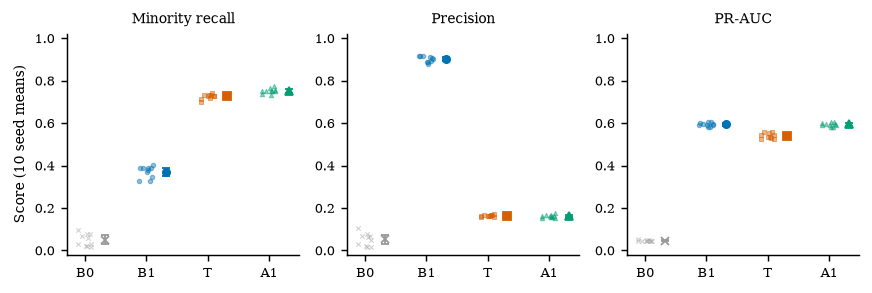

In [11]:
OKABE = {"B0": "#999999", "B1": "#0072B2", "T": "#D55E00", "A1": "#009E73"}
MARK = {"B0": "x", "B1": "o", "T": "s", "A1": "^"}
LABEL = {"B0": "B0 dummy", "B1": "B1 unweighted", "T": "T weighted", "A1": "A1 threshold"}
plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
                     "legend.fontsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7, "pdf.fonttype": 42,
                     "axes.spines.top": False, "axes.spines.right": False, "savefig.bbox": "tight",
                     "figure.dpi": 130})

seed_means = res.groupby(["condition", "seed"])[["recall", "precision", "pr_auc"]].mean().reset_index()
t975 = stats.t.ppf(0.975, df=len(CFG.seeds) - 1)

fig, axes = plt.subplots(1, 3, figsize=(6.75, 2.3))
jitter = np.random.default_rng(0).uniform(-0.12, 0.12, len(CFG.seeds))       # spread the dots horizontally
for ax, metric, title in zip(axes, ["recall", "precision", "pr_auc"], ["Minority recall", "Precision", "PR-AUC"]):
    for i, cond in enumerate(ORDER):
        v = seed_means.loc[seed_means.condition == cond, metric].values      # 10 seed means
        ax.scatter(i + jitter, v, s=6, color=OKABE[cond], alpha=0.45, marker=MARK[cond], linewidths=0.6)
        ci = t975 * v.std(ddof=1) / np.sqrt(len(v))
        ax.errorbar(i + 0.32, v.mean(), yerr=ci, fmt=MARK[cond], color=OKABE[cond], ms=4, capsize=2, lw=1)
    ax.set_xticks(range(len(ORDER)), ORDER)
    ax.set_title(title)
    ax.set_ylim(-0.02, 1.02)
axes[0].set_ylabel("Score (10 seed means)")
fig.tight_layout()
fig.savefig(WORK / "figures" / "fig1_metrics.pdf")
plt.show()

*Figure 1. Minority recall, precision and PR-AUC for the four conditions. Small symbols: the mean over 5 outer folds for each of 10 seeds; large symbols with bars: mean and 95% CI (t-distribution over the 10 seed means, which ignores the shared dataset; see Section 6.3).*

The second figure shows **why** T and A1 behave alike: both are just *operating points* on precision–recall curves.

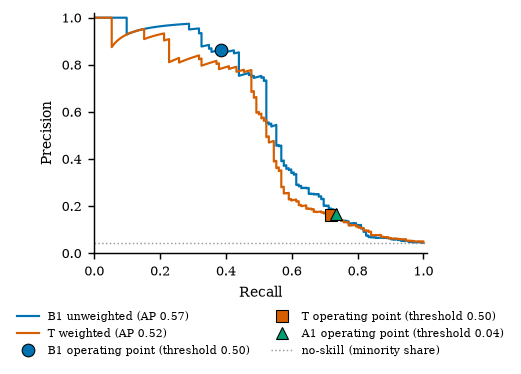

In [12]:
fig, ax = plt.subplots(figsize=(3.3, 2.4))
y_oof = oof["y"].astype(int)
for cond in ("B1", "T"):
    prec, rec, _ = precision_recall_curve(y_oof, oof[cond])
    ax.plot(rec, prec, color=OKABE[cond], lw=1.2,
            label=f"{LABEL[cond]} (AP {average_precision_score(y_oof, oof[cond]):.2f})")
points = {"B1": (oof["B1"], 0.5), "T": (oof["T"], 0.5), "A1": (oof["B1"], y.mean())}
for cond, (p, thr) in points.items():
    pred = p >= thr
    ax.plot(recall_score(y_oof, pred), precision_score(y_oof, pred), MARK[cond], color=OKABE[cond], ms=7,
            mec="black", mew=0.6, label=f"{cond} operating point (threshold {thr:.2f})")
ax.axhline(y.mean(), color="#999999", ls=":", lw=0.8, label="no-skill (minority share)")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_xlim(0, 1.01); ax.set_ylim(0, 1.02)
ax.legend(frameon=False, fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)   # below the axes
fig.savefig(WORK / "figures" / "fig2_pr_curves.pdf")
plt.show()

**What just happened?** In the PR-curve plot (out-of-fold predictions of seed 0), B1 and T trace *similar* curves (T's is slightly lower: its AP is smaller), and the three operating points show the real difference between the conditions: **B1 at 0.5** sits at high precision / low recall, while **T at 0.5** and **A1 at the prevalence threshold** sit next to each other at high recall / low precision. Weighting mostly *moves along the curve*, it does not move the curve up. This one figure explains H1–H4 better than the table.

In [13]:
def fmt(mean, std, bold=False):
    core = f"{mean:.3f}"
    return (f"$\\mathbf{{{core}}} \\pm {std:.3f}$" if bold else f"${core} \\pm {std:.3f}$")


metrics_tex = {"recall": "Recall $\\uparrow$", "precision": "Precision $\\uparrow$", "pr_auc": "PR-AUC $\\uparrow$",
               "brier": "Brier $\\downarrow$"}
agg = res.groupby("condition")[list(metrics_tex)].agg(["mean", "std"]).loc[ORDER]
table = pd.DataFrame(index=[LABEL[c] for c in ORDER])
for m, header in metrics_tex.items():
    means, stds = agg[(m, "mean")], agg[(m, "std")]
    best = means.idxmin() if m == "brier" else means.idxmax()
    table[header] = [fmt(means[c], stds[c], bold=(c == best)) for c in ORDER]
table = table.reset_index(names="Condition")          # condition names as a normal first column
latex = table.to_latex(index=False, escape=False, column_format="lcccc", label="tab:main", position="t",
                       caption="Outer-fold results (mean $\\pm$ std over 10 seeds $\\times$ 5 folds). "
                               "Best mean per column in bold. Synthetic fraud-like data, 4\\% minority class.")
(WORK / "table_main.tex").write_text(latex)
print(latex)

\begin{table}[t]
\caption{Outer-fold results (mean $\pm$ std over 10 seeds $\times$ 5 folds). Best mean per column in bold. Synthetic fraud-like data, 4\% minority class.}
\label{tab:main}
\begin{tabular}{lcccc}
\toprule
Condition & Recall $\uparrow$ & Precision $\uparrow$ & PR-AUC $\uparrow$ & Brier $\downarrow$ \\
\midrule
B0 dummy & $0.050 \pm 0.043$ & $0.052 \pm 0.046$ & $0.046 \pm 0.004$ & $0.083 \pm 0.008$ \\
B1 unweighted & $0.370 \pm 0.098$ & $\mathbf{0.902} \pm 0.086$ & $\mathbf{0.594} \pm 0.087$ & $\mathbf{0.026} \pm 0.003$ \\
T weighted & $0.726 \pm 0.067$ & $0.163 \pm 0.017$ & $0.541 \pm 0.094$ & $0.132 \pm 0.007$ \\
A1 threshold & $\mathbf{0.752} \pm 0.064$ & $0.162 \pm 0.019$ & $0.594 \pm 0.087$ & $0.026 \pm 0.003$ \\
\bottomrule
\end{tabular}
\end{table}



---
## 8. An auto-generated results paragraph

> 💡 **In plain English:** the computer writes the results paragraph from the numbers, so text and tables always agree.

Typing numbers from a table into a paper by hand is a classic source of errors. Instead we **generate** the results paragraph from the test results, so the text, the table and the figures always agree. A test at the end checks that every number in the paragraph appears in the computed results.

In [14]:
def pfmt(p: float) -> str:
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


def results_paragraph(tests: pd.DataFrame, agg: pd.DataFrame) -> str:
    t = tests.set_index("hypothesis")
    rec = agg["recall"]["mean"]; prec = agg["precision"]["mean"]; ap = agg["pr_auc"]["mean"]
    word = lambda h: "significant" if t.loc[h, "reject_H0"] else "not significant"
    s = []
    s.append(f"Class-balanced training (T) changed minority recall from {rec['B1']:.3f} (B1) to {rec['T']:.3f}, "
             f"a difference of {t.loc['H1', 'mean_diff']:+.3f} (95% CI [{t.loc['H1', 'ci_low']:.3f}, {t.loc['H1', 'ci_high']:.3f}], "
             f"corrected resampled t-test, Holm-adjusted {pfmt(t.loc['H1', 'p_holm'])}; {word('H1')}).")
    s.append(f"Precision changed from {prec['B1']:.3f} to {prec['T']:.3f} ({t.loc['H2', 'mean_diff']:+.3f}, "
             f"Holm-adjusted {pfmt(t.loc['H2', 'p_holm'])}; {word('H2')}).")
    s.append(f"Ranking quality changed by {t.loc['H3', 'mean_diff']:+.3f} in PR-AUC ({ap['B1']:.3f} vs {ap['T']:.3f}; "
             f"95% CI [{t.loc['H3', 'ci_low']:.3f}, {t.loc['H3', 'ci_high']:.3f}], Holm-adjusted {pfmt(t.loc['H3', 'p_holm'])}; {word('H3')}).")
    s.append(f"Moving the threshold of the unweighted model to the training prevalence (A1) gave a recall of {rec['A1']:.3f}; "
             f"compared with A1, weighting changed recall by {t.loc['H4', 'mean_diff']:+.3f} "
             f"(95% CI [{t.loc['H4', 'ci_low']:.3f}, {t.loc['H4', 'ci_high']:.3f}], Holm-adjusted {pfmt(t.loc['H4', 'p_holm'])}; {word('H4')}).")
    s.append(f"All conditions clearly outperformed the stratified dummy baseline (recall {rec['B0']:.3f}, PR-AUC {ap['B0']:.3f}).")
    return " ".join(s)


paragraph = results_paragraph(tests, agg)
(WORK / "results_paragraph.md").write_text(paragraph)
display(Markdown("> " + paragraph))

# Consistency test: every 3-decimal number in the text must exist in the computed results
numbers_in_text = {float(x) for x in re.findall(r"[-+]?\d+\.\d{3}", paragraph)}
computed = set(np.round(agg.values.ravel(), 3)) | set(np.round(tests[["mean_diff", "ci_low", "ci_high", "p_holm"]].values.ravel(), 3))
computed |= {0.001}                                       # the "p < 0.001" reporting threshold
missing = {x for x in numbers_in_text if not any(np.isclose(x, c, atol=5e-4) for c in computed)}
assert not missing, missing
print(f"all {len(numbers_in_text)} numbers in the paragraph match the computed results")

> Class-balanced training (T) changed minority recall from 0.370 (B1) to 0.726, a difference of +0.356 (95% CI [0.267, 0.445], corrected resampled t-test, Holm-adjusted p < 0.001; significant). Precision changed from 0.902 to 0.163 (-0.739, Holm-adjusted p < 0.001; significant). Ranking quality changed by -0.053 in PR-AUC (0.594 vs 0.541; 95% CI [-0.082, -0.024], Holm-adjusted p = 0.001; significant). Moving the threshold of the unweighted model to the training prevalence (A1) gave a recall of 0.752; compared with A1, weighting changed recall by -0.026 (95% CI [-0.069, 0.017], Holm-adjusted p = 0.235; not significant). All conditions clearly outperformed the stratified dummy baseline (recall 0.050, PR-AUC 0.046).

all 21 numbers in the paragraph match the computed results

### 8.1 Decision against the pre-registered rule

In [15]:
h4 = tests.set_index("hypothesis").loc["H4"]
recommend_weighting = bool(h4["reject_H0"] and h4["mean_diff"] >= CFG.sesoi_recall)
print("Decision rule:", PLAN["decision_rule"])
print(f"H4: recall(T) - recall(A1) = {h4['mean_diff']:+.3f}, Holm p = {h4['p_holm']:.3g}, SESOI = {CFG.sesoi_recall}")
print("=> Recommend class-balanced weighting:", recommend_weighting)

# Was the plan changed after registration?
assert hashlib.sha256((WORK / "preregistration.yaml").read_text().encode()).hexdigest() == PLAN_SHA
DEVIATIONS = []   # list every deviation from the plan here, with a reason (none in this study)
print("pre-registration unchanged (SHA-256 verified); deviations from the plan:", DEVIATIONS or "none")

Decision rule: Recommend weighting only if H4 is rejected in favour of T with a recall gain >= SESOI.
H4: recall(T) - recall(A1) = -0.026, Holm p = 0.235, SESOI = 0.05
=> Recommend class-balanced weighting: False
pre-registration unchanged (SHA-256 verified); deviations from the plan: none


**What just happened?** The pre-registered decision rule says: **do not recommend class-balanced weighting**, because it is not better than the free alternative (moving the threshold) by at least the SESOI. The plan file is unchanged (its SHA-256 still matches), and there are no deviations to report.

### 8.2 Exploratory analysis: calibration (not pre-registered)

Section 2 mentioned that weighting can distort predicted probabilities. This was listed as **exploratory**, so we report it without a confirmatory test. A model is **calibrated** if, among cases with predicted probability ≈ 0.1, about 10% are fraud. A simple summary: the average predicted probability should be close to the true minority share.

In [16]:
calib = res[res.condition.isin(["B1", "T"])].groupby("condition")[["mean_pred", "brier"]].mean()
calib["true_minority_share"] = y.mean()
print(calib.round(4))

           mean_pred   brier  true_minority_share
condition                                        
B1            0.0437  0.0261                0.044
T             0.3241  0.1322                0.044


**What just happened?** The unweighted model's average predicted probability (0.044) matches the true fraud rate (0.044), while the weighted model predicts on average 0.324, about seven times too high, and its Brier score is five times worse (0.132 vs 0.026). This agrees with van den Goorbergh et al. (2022). It matters in practice: fraud teams often use the probability itself (to prioritise cases or compute expected loss), and those numbers would be badly wrong after weighting. Because this analysis was not pre-registered, a paper would report it as **exploratory** and suggest a confirmatory study.

---
## 9. Limitations and threats to validity

> 💡 **In plain English:** we honestly list what could make our conclusion wrong.

A standard way to organise threats (common in empirical software engineering, e.g. Wohlin et al., *Experimentation in Software Engineering*, 2012; see also [notebook 02](02_experiment_design_for_ml.ipynb), Section 5) uses four types:

| Type | Question | Threats in *this* study | Mitigation / what would fix it |
|---|---|---|---|
| **Internal validity** | Is the effect really caused by the treatment? | tuning could favour one condition; implementation bugs | same grid and inner CV for B1 and T; ablation re-uses the B1 model; sanity checks (B0, identical PR-AUC for A1) |
| **External validity** | Does it generalise? | **synthetic data**; one dataset; one imbalance ratio (≈ 4%); one model family (linear) | repeat on several real datasets and imbalance ratios; add tree ensembles (gradient boosting) |
| **Construct validity** | Do the metrics measure what matters? | recall at a fixed threshold is not the business objective; real fraud has costs, delays in labels and drift | add a cost-based metric (Section 11) and time-based splits on real data |
| **Conclusion (statistical) validity** | Are the statistical conclusions sound? | the 50 folds are dependent; all seeds share one dataset; the corrected t-test is an approximation | corrected t-test + Holm, a seed-level bootstrap as a check, a pre-registered SESOI; better: many datasets (Demšar, *JMLR*, 2006) |

**Further limitations:** we tuned only $C$; we did not try re-sampling methods (SMOTE, under-sampling) or focal loss; label noise was fixed at 1%; and the study answers a question about *logistic regression*, not about all models.

> ⚠️ **Common mistake:** a limitations section that lists only harmless points ("we could use more data"). Reviewers and product managers respect authors who name the threats that could actually overturn the conclusion, here the synthetic data and the single model family.

---
## 10. The reproducibility package

> 💡 **In plain English:** we pack everything a colleague needs to re-run the study and prove that it reproduces a stored result.

Everything a colleague needs to re-run and audit the study, written to one folder (in real life: a git repository + a release with a DOI, see notebook 04):

In [17]:
PKG = WORK / "repro_package"
PKG.mkdir()
for name in ("preregistration.yaml", "results_per_fold.csv", "hypothesis_tests.csv", "bootstrap_cis.csv",
             "table_main.tex", "results_paragraph.md"):
    shutil.copy(WORK / name, PKG / name)
shutil.copytree(WORK / "figures", PKG / "figures")

(PKG / "config.yaml").write_text(yaml.safe_dump(asdict(CFG) | {"seeds": list(CFG.seeds), "C_grid": list(CFG.C_grid)},
                                                sort_keys=False))
(PKG / "seeds.json").write_text(json.dumps({"study_seeds": list(CFG.seeds), "data_seed": CFG.data_seed,
                                            "bootstrap_seeds": {"ours": 1, "scipy_percentile": 2, "scipy_bca": 3}}))
env_pins = [f"python=={platform.python_version()}"] + [f"{p}=={metadata.version(p)}" for p in
            ("numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "PyYAML", "threadpoolctl")]
(PKG / "requirements.txt").write_text("\n".join(env_pins) + "\n")

t = tests.set_index("hypothesis")
model_card = f"""# Model card: fraud-recall study models (research artefact)

| Section | Content |
|---|---|
| Model details | Logistic regression (scikit-learn {sklearn.__version__}), standardised inputs; B1 unweighted, T class_weight='balanced'; C tuned by inner 3-fold CV on PR-AUC |
| Intended use | Research comparison only; **not** a production fraud model |
| Factors | No customer subgroups exist in the synthetic data; a fairness audit is required before any real deployment |
| Metrics | Minority recall (primary), precision, PR-AUC; Brier score and mean predicted probability (exploratory) |
| Evaluation data | Outer folds of 10 x 5 nested CV on synthetic data (n = {len(y)}, minority share {y.mean():.1%}) |
| Training data | sklearn make_classification, seed {CFG.data_seed}; data SHA-256 {DATA_SHA[:16]}... |
| Quantitative analyses | recall T - B1 = {t.loc['H1', 'mean_diff']:+.3f}; PR-AUC T - B1 = {t.loc['H3', 'mean_diff']:+.3f}; recall T - A1 = {t.loc['H4', 'mean_diff']:+.3f} (see hypothesis_tests.csv) |
| Ethical considerations | More recall means more blocked legitimate payments (false positives); these costs can fall unevenly on customer groups |
| Caveats | Synthetic data, one model family, one imbalance ratio; see threats to validity |
"""
(PKG / "MODEL_CARD.md").write_text(model_card)
(PKG / "README.md").write_text(
    "# Reproducibility package\n\n1. `pip install -r requirements.txt` (Python version on the first line)\n"
    "2. Re-run the notebook `06_industry_running_a_research_project_end_to_end.ipynb` with `config.yaml`\n"
    "3. Check `MANIFEST.sha256` with `sha256sum -c MANIFEST.sha256`\n\n"
    f"Pre-registration SHA-256: `{PLAN_SHA}`\nData SHA-256: `{DATA_SHA}`\n")

# Manifest of every file (same format as the `sha256sum` tool)
files = sorted(p for p in PKG.rglob("*") if p.is_file())
manifest = "".join(f"{hashlib.sha256(p.read_bytes()).hexdigest()}  {p.relative_to(PKG).as_posix()}\n" for p in files)
(PKG / "MANIFEST.sha256").write_text(manifest)

for p in sorted(PKG.rglob("*")):
    if p.is_file():
        print(f"{p.relative_to(PKG).as_posix():32s} {p.stat().st_size:>8,d} bytes")

MANIFEST.sha256                     1,091 bytes
MODEL_CARD.md                       1,135 bytes
README.md                             437 bytes
bootstrap_cis.csv                     710 bytes
config.yaml                           341 bytes
figures/fig1_metrics.pdf           29,286 bytes
figures/fig2_pr_curves.pdf         27,043 bytes
hypothesis_tests.csv                  846 bytes
preregistration.yaml                1,609 bytes
requirements.txt                      130 bytes
results_paragraph.md                  720 bytes
results_per_fold.csv               25,959 bytes
seeds.json                            137 bytes
table_main.tex                        780 bytes


**The real test of a package: can we reproduce a stored number from it?** We reload the saved config, re-create the data, re-run one outer fold (seed 3, fold 2) from scratch and compare with the stored results.

In [18]:
cfg_loaded = yaml.safe_load((PKG / "config.yaml").read_text())
X2, y2 = make_classification(
    n_samples=cfg_loaded["n_samples"], n_features=cfg_loaded["n_features"], n_informative=cfg_loaded["n_informative"],
    n_redundant=cfg_loaded["n_redundant"], weights=[1 - cfg_loaded["minority_share"]], flip_y=cfg_loaded["label_noise"],
    class_sep=cfg_loaded["class_sep"], random_state=cfg_loaded["data_seed"])
data_sha2 = hashlib.sha256(np.ascontiguousarray(X2).tobytes() + np.ascontiguousarray(y2).tobytes()).hexdigest()
assert data_sha2 == DATA_SHA, "the data could not be re-created"

seed, fold = 3, 2
tr, te = list(StratifiedKFold(cfg_loaded["outer_folds"], shuffle=True, random_state=seed).split(X2, y2))[fold]
C = select_C(X2[tr], y2[tr], "balanced", seed)
scaler, model = fit_logreg(X2[tr], y2[tr], C, "balanced")
p = model.predict_proba(scaler.transform(X2[te]))[:, 1]
again = score(y2[te], (p >= 0.5).astype(int), p)

stored = pd.read_csv(PKG / "results_per_fold.csv").query("seed == @seed and fold == @fold and condition == 'T'").iloc[0]
for k in ("recall", "precision", "pr_auc"):
    print(f"{k:9s} stored {stored[k]:.6f} | re-run {again[k]:.6f}")
    assert np.isclose(stored[k], again[k])
check = {line.split("  ")[1]: line.split("  ")[0] for line in manifest.splitlines()}
assert all(hashlib.sha256((PKG / f).read_bytes()).hexdigest() == h for f, h in check.items())
print("re-run matches the stored result; all", len(check), "files match MANIFEST.sha256")

recall    stored 0.653846 | re-run 0.653846
precision stored 0.161905 | re-run 0.161905
pr_auc    stored 0.459348 | re-run 0.459348
re-run matches the stored result; all 13 files match MANIFEST.sha256


**What just happened?** From the package alone (config + code) we re-created the data with the same SHA-256 and reproduced a stored fold result exactly, and every file matches its checksum. This is the "reproducible" level of notebook 04; "replicable" would need new data.

---
## 11. Inside an industry research team: from research to product

> 💡 **In plain English:** in a company the study ends with a decision memo, then a live test, then a careful rollout.

In a company, the study above is one stage of a longer path. The goal is not a publication but a **decision** the product team can trust.

```
 question from product -> design doc / pre-registration (reviewed) -> offline study (this notebook)
   -> research review ("experiment review" meeting) -> decision memo
   -> shadow mode (score live traffic, take no action) -> online A/B test with guardrail metrics
   -> launch + monitoring + rollback plan -> (optional) external paper / blog after legal & privacy review
```

| Stage | Owner | Output | Repo notebook |
|---|---|---|---|
| Problem framing | product manager + applied scientist | design doc with the decision and its metric | [ML system design](../22_ML_System_Design/08_industry_system_design_case_study.ipynb) |
| Offline study | applied / research scientist | pre-registration, results, reproducibility package | this notebook |
| Review | peers, a senior scientist | sign-off or requested changes | |
| Productionisation | ML engineer | pipeline, tests, model registry entry | [end-to-end MLOps](../15_MLOps/15_industry_end_to_end_mlops_pipeline.ipynb) |
| Online test | data scientist + product | A/B test with business and guardrail metrics | [A/B test report](../03_Machine_Learning/11_ab_testing/02_industry_ab_test_analysis_report.ipynb) |
| Rollout & monitoring | ML engineer / on-call | staged rollout, drift and performance alerts | [rollout strategies](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb), [monitoring](../15_MLOps/06_monitoring) |
| Responsible AI review | risk / ethics / legal | fairness audit, model card sign-off | [responsible AI product review](../00_AI_Fundamentals/07_industry_responsible_ai_product_review.ipynb) |

**What industry adds to the academic method:** the metric is tied to **money and risk**; the decision has a **deadline**; data is **confidential** (papers need legal and privacy approval); and offline results must be confirmed **online**, because offline metrics are only a proxy.

### 11.1 From metrics to a business decision

Product does not care about recall; it cares about **cost**. Suppose a missed fraud costs \$200 and blocking a legitimate payment (customer friction, support call) costs \$10 (illustrative numbers that the product team would supply). For calibrated probabilities, the cost-minimising threshold is $\tau^\* = c_{FP} / (c_{FP} + c_{FN})$ (Elkan, 2001). We compare the expected cost per 1,000 transactions on the out-of-fold predictions of seed 0:

In [19]:
COST_FN, COST_FP = 200.0, 10.0                      # $ per missed fraud, $ per false alarm (illustrative)
tau_star = COST_FP / (COST_FP + COST_FN)


def cost_per_1000(y_true, p, threshold):
    pred = p >= threshold
    fn = np.sum((y_true == 1) & ~pred); fp = np.sum((y_true == 0) & pred)
    return 1000 * (COST_FN * fn + COST_FP * fp) / len(y_true)


options = {
    "B1 unweighted, threshold 0.5": (oof["B1"], 0.5),
    "T weighted, threshold 0.5": (oof["T"], 0.5),
    "A1 unweighted, threshold = prevalence": (oof["B1"], y.mean()),
    f"B1 unweighted, cost-optimal threshold {tau_star:.3f}": (oof["B1"], tau_star),
}
cost_table = pd.DataFrame({name: {"threshold": thr, "cost_per_1000_usd": cost_per_1000(y_oof, p, thr),
                                  "recall": recall_score(y_oof, p >= thr), "precision": precision_score(y_oof, p >= thr)}
                           for name, (p, thr) in options.items()}).T
print(cost_table.round(3))

                                             threshold  cost_per_1000_usd  recall  precision
B1 unweighted, threshold 0.5                     0.500           5426.667   0.386      0.864
T weighted, threshold 0.5                        0.500           4080.000   0.720      0.164
A1 unweighted, threshold = prevalence            0.044           3960.000   0.735      0.166
B1 unweighted, cost-optimal threshold 0.048      0.048           3900.000   0.727      0.176


**What just happened?** With these costs the cost-optimal threshold is $\tau^\* = 10/210 \approx 0.048$, close to the prevalence. The unweighted model at $\tau^\*$ is the cheapest option (\$3,900 per 1,000 transactions), followed by A1 (\$3,960), the weighted model at 0.5 (\$4,080) and, far behind, the unweighted model at 0.5 (\$5,427). So the *business* answer agrees with the statistics: the gain comes from choosing the right threshold, which needs **calibrated** probabilities, and weighting destroys calibration. (These are seed-0 out-of-fold numbers with illustrative costs; the real decision needs the product team's real costs and an online test.)

In [20]:
best_option = cost_table["cost_per_1000_usd"].astype(float).idxmin()
memo = f"""## Decision memo: class-balanced training for the fraud model

**Question (from product):** should we retrain the fraud model with class-balanced weights?

**Answer:** {'Yes' if recommend_weighting else 'No, not as a way to improve the model'}. In a pre-registered study (10 seeds x nested 5-fold CV), weighting raised recall at the default threshold by {t.loc['H1', 'mean_diff']:+.2f}, but an unweighted model with a moved threshold achieved {'a similar' if abs(t.loc['H4', 'mean_diff']) < CFG.sesoi_recall else 'a different'} recall (difference {t.loc['H4', 'mean_diff']:+.2f}), and weighting {'lowered' if t.loc['H3', 'mean_diff'] < 0 else 'did not improve'} ranking quality (PR-AUC {t.loc['H3', 'mean_diff']:+.3f}) and distorted the predicted probabilities.

**Recommendation:** keep the unweighted (calibrated) model and choose the alert threshold from the cost of errors. With illustrative costs (\\$200 per missed fraud, \\$10 per false alarm) the cheapest option offline was: *{best_option}*.

**Next steps:** (1) replicate on 3 months of real, time-split transaction data; (2) shadow-mode run for 2 weeks; (3) A/B test with fraud loss as the primary metric and false-decline rate as a guardrail; (4) fairness audit of false declines.

**Confidence / risks:** synthetic data and one model family (see threats to validity). Reproducibility package: config, seeds, results, figures, model card, SHA-256 manifest.
"""
(PKG / "DECISION_MEMO.md").write_text(memo)
display(Markdown(memo))

## Decision memo: class-balanced training for the fraud model

**Question (from product):** should we retrain the fraud model with class-balanced weights?

**Answer:** No, not as a way to improve the model. In a pre-registered study (10 seeds x nested 5-fold CV), weighting raised recall at the default threshold by +0.36, but an unweighted model with a moved threshold achieved a similar recall (difference -0.03), and weighting lowered ranking quality (PR-AUC -0.053) and distorted the predicted probabilities.

**Recommendation:** keep the unweighted (calibrated) model and choose the alert threshold from the cost of errors. With illustrative costs (\$200 per missed fraud, \$10 per false alarm) the cheapest option offline was: *B1 unweighted, cost-optimal threshold 0.048*.

**Next steps:** (1) replicate on 3 months of real, time-split transaction data; (2) shadow-mode run for 2 weeks; (3) A/B test with fraud loss as the primary metric and false-decline rate as a guardrail; (4) fairness audit of false declines.

**Confidence / risks:** synthetic data and one model family (see threats to validity). Reproducibility package: config, seeds, results, figures, model card, SHA-256 manifest.


**What just happened?** The memo is generated from the same numbers as the paper paragraph, written for a non-statistician, with a clear answer, the evidence, the risks and the next steps. In many companies such memos are reviewed in a weekly "experiment review" and archived, so future teams can find what was already tried.

> 🎓 **Exam / interview tip (applied-scientist interviews):** "Your offline metric improved but the A/B test showed nothing. Why?" Possible reasons: the offline metric is a poor proxy for the business metric, train/serve skew, distribution shift, leakage in the offline evaluation, too little power in the A/B test, or the improvement sits at thresholds the product never uses.

In [21]:
total_runtime = time.perf_counter() - STUDY_START
shutil.rmtree(WORK)                                  # delete the working folder and the package
print(f"total notebook compute time: {total_runtime:.0f} s | temporary folder removed: {not WORK.exists()}")

total notebook compute time: 47 s | temporary folder removed: True


---
## 12. Summary

> 💡 **In plain English:** the 11 steps of a research project in one table.

| Step | What we did | Tool / method |
|---|---|---|
| 1 Research question | specific, decision-linked RQ; 4 hypotheses; a SESOI | |
| 2 Literature | real, checked references; the gap | |
| 3 Pre-registration | plan with decision and stopping rules, SHA-256 fingerprint | YAML + hashlib |
| 4 Design | 2 baselines, treatment, threshold ablation; 10 seeds × nested 5×3 CV; paired | scikit-learn |
| 5 Run | 1300 fits, sanity checks before statistics | |
| 6 Statistics | corrected resampled t-test (checked vs `scipy.stats.ttest_rel`), Holm (checked vs brute force/statsmodels), bootstrap (checked vs `scipy.stats.bootstrap`), Wilcoxon | SciPy |
| 7 Figures & table | colour-blind palette + markers, vector PDF, CI stated, booktabs LaTeX | matplotlib, pandas |
| 8 Results text | generated from numbers, consistency-tested; decision via the pre-registered rule | |
| 9 Validity | internal / external / construct / conclusion threats | |
| 10 Package | config, seeds, env, results, figures, model card, manifest; a stored result re-computed | |
| 11 Industry | cost-based threshold, decision memo, shadow → A/B → rollout | |

## Practice problems

**1. (Easy)** Why does the ablation A1 re-use the *same fitted model* as B1 instead of training a new one?
<details><summary>Show solution</summary>

So that the only difference between B1 and A1 is the threshold. Any difference in recall is then caused by the threshold alone, which isolates the "threshold effect" of class weighting. Training a new model would mix in tuning and fitting noise.
</details>

**2. (Easy)** The naive paired t-test gave a much smaller p-value than the corrected one. Which should you report, and why?
<details><summary>Show solution</summary>

The corrected one (it was pre-registered, and it is appropriate). CV folds share training data, so the 50 differences are positively correlated and the naive variance estimate is too small, giving p-values that are too optimistic (inflated type-I error; Dietterich 1998, Nadeau & Bengio 2003).
</details>

**3. (Medium, coding)** Compute Bonferroni-adjusted p-values for the four tests and compare them with Holm. Which hypotheses are rejected by each method?
<details><summary>Show solution</summary>

```python
bonf = np.minimum(1, tests["p"] * len(tests))
print(pd.DataFrame({"hyp": tests.hypothesis, "p": tests.p, "holm": tests.p_holm, "bonferroni": bonf,
                    "rej_holm": tests.p_holm <= 0.05, "rej_bonf": bonf <= 0.05}))
```
Holm's adjusted p-values are always ≤ Bonferroni's, so Holm rejects at least the same hypotheses (here typically the same set, because the effects are either very large or near zero).
</details>

**4. (Medium)** A colleague suggests adding 10 more seeds "because H4 was close to significant". What do you answer?
<details><summary>Show solution</summary>

The stopping rule was fixed at 10 seeds. Adding runs *because* a result is close to the threshold is optional stopping, which inflates the false-positive rate. If more evidence is needed, register a new, separate (confirmatory) study, ideally on new or real data, and report the current one as is. Also note that more seeds on the *same* dataset add little information about generalisation.
</details>

**5. (Medium, coding)** Add a condition **T-cal**: the weighted model with its probabilities corrected back to the original prior using $\text{odds}_{\text{cal}} = \text{odds}_w \cdot n_1/n_0$. Show that its mean predicted probability is close to the minority share.
<details><summary>Show solution</summary>

```python
def unweight(p_w, prior):
    odds = p_w / (1 - p_w) * prior / (1 - prior)      # undo the n0/n1 odds multiplication
    return odds / (1 + odds)

p_cal = unweight(oof["T"], y.mean())
print(round(oof["T"].mean(), 3), "->", round(p_cal.mean(), 3), "vs minority share", round(y.mean(), 3))
```
The corrected probabilities have a mean close to the minority share (the correction is exact only for an unregularised, well-specified model, so a small gap can remain).
</details>

**6. (Hard)** List two changes to the design that would most improve **external validity**, and explain how the statistics would change.
<details><summary>Show solution</summary>

(1) Use several real datasets (e.g. public fraud/credit/medical imbalanced datasets) and (2) several model families (logistic regression, gradient boosting) and imbalance ratios. With many datasets, the unit of analysis becomes the **dataset**: compare methods with a Wilcoxon signed-rank test across datasets or a Friedman test with post-hoc tests for more than two methods (Demšar, 2006), which avoids the dependence problem of folds within one dataset.
</details>

**7. (Hard, coding)** Change `CFG` to a minority share of 1% (`StudyConfig(minority_share=0.01)`), re-run Sections 4–6 and describe what happens to the recall estimates and their confidence intervals.
<details><summary>Show solution</summary>

Create `CFG = StudyConfig(minority_share=0.01)` and re-run from Section 4.1. With only about 30 minority examples in total (about 6 per outer test fold), each fold's recall can take only a few values (0, 1/6, 2/6, ...), so fold-level recall becomes very noisy, the std and the corrected CIs widen a lot, and the tests lose power. This shows why rare-event studies need more data (or pooled out-of-fold evaluation) before conclusions can be drawn.
</details>

## Resources

- C. Nadeau and Y. Bengio, "Inference for the Generalization Error", *Machine Learning* 52, 2003; R. Bouckaert and E. Frank, "Evaluating the Replicability of Significance Tests for Comparing Learning Algorithms", PAKDD 2004.
- T. Dietterich, "Approximate Statistical Tests for Comparing Supervised Classification Learning Algorithms", *Neural Computation* 10(7), 1998.
- J. Demšar, "Statistical Comparisons of Classifiers over Multiple Data Sets", *JMLR* 7, 2006.
- S. Holm, "A Simple Sequentially Rejective Multiple Test Procedure", *Scandinavian Journal of Statistics* 6, 1979.
- B. Efron and R. Tibshirani, *An Introduction to the Bootstrap*, Chapman & Hall, 1993.
- C. Elkan, "The Foundations of Cost-Sensitive Learning", IJCAI 2001; H. He and E. Garcia, "Learning from Imbalanced Data", *IEEE TKDE* 21(9), 2009.
- C. Wohlin et al., *Experimentation in Software Engineering*, Springer, 2012 (threats to validity).
- Center for Open Science, OSF Registries (pre-registration templates): https://www.cos.io/initiatives/prereg

### Related notebooks
- [Model comparison and selection (industry)](../03_Machine_Learning/06_model_evaluation/03_industry_model_comparison_and_selection.ipynb), [Hyper-parameter optimisation](../03_Machine_Learning/06_model_evaluation/02_hyperparameter_optimization.ipynb), [Model calibration](../03_Machine_Learning/01_supervised/13_model_calibration.ipynb)
- [A/B testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb), [MLflow](../15_MLOps/01_experiment_tracking/01_mlflow.ipynb), [Bias & fairness](../19_AI_Ethics_and_Safety/01_bias_fairness.ipynb)

### Back to the start of the module
⬅️ [01 Research methodology and literature review](01_research_methodology_and_literature_review.ipynb)

## Next notebook

This is the last notebook of the module. ➡️ Return to the [Research Methods README](README.md) for the module map and quick-revision notes, or to the [repository README](../README.md) to choose your next module.